# 09 · Robustez del detector de QRS

El detector de QRS es el de Pan y Tompkins (1985) con seis etapas que se le agregaron:
- el reaprendizaje de los umbrales;
- las cinco mejoras de `02` §2.

Cada una protege contra una falla que se vio en desarrollo. En `02` se justificaron con una ablación sin valores p. Acá se revisan con el criterio de robustez (`docs/criterio_robustez.md`), con dos agregados del 2026-11-21:
- **el de las mejoras del QRS**, escrito y subido antes de correr este notebook;
- **el de las fallas reales**, escrito después de una prueba rápida con 16 registros y antes de esta corrida. Agrega una segunda vía para mostrar que una etapa protege: que sin ella alguna noche real de desarrollo quede más de un punto peor en % de RR corregidos. Por eso la decisión se informa con las dos reglas.

El notebook tiene tres secciones:

1. **Pruebas de estrés y fallas reales** (sección 1): se imitan las fallas en los 47 registros de desarrollo, sin usar etiquetas, y se mide si cada etapa protege. También se mira qué pasa sin cada etapa en el ECG original.
2. **¿Alguna etapa empeora el detector?** (sección 2): exactitud en validación cruzada y P2, sacando una etapa por vez del detector final de `08`.
3. **Decisión** (sección 3), con la regla de sencillez de `07` para las etapas que no protegen, y el chequeo de la combinación.

Test no se usa.

In [1]:
import json
import os
import sys
import zlib
from concurrent.futures import ProcessPoolExecutor
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.signal.windows import tukey
from scipy.stats import binomtest, spearmanr

import src.qrs.pan_tompkins as pt_mod
from src.config import ECG_FILTER, QRS_TOLERANCE_S, SPLIT_CSV
from src.data import load_apnea_labels, load_ecg
from src.estadistica import holm, p_bootstrap
from src.evaluation.cv import GRILLA_W, auc, cv_c, replicar_personas, sorteos_personas
from src.features.build import record_series
from src.features.detector import c_score, evaluable, fit_c, minute_table, save_params, youden_threshold
from src.preprocessing.filters import apply_zero_phase, design_bandpass
from src.qrs.pan_tompkins import detect_r_peaks, refine_peaks_parabolic, validate_against_reference
from src.qrs.rr_clean import clean_rr
from src.viz.plots import ANCHO, APNEA, GRIS, NORMAL, save, setup

setup()
split = pd.read_csv(SPLIT_CSV)
DEV = split[split.set == "dev"].record.tolist()
RAPIDO = bool(os.environ.get("NB09_RAPIDO"))   # solo para probar el código: 16 registros (con los casos difíciles) y pocos sorteos
if RAPIDO:
    DEV = DEV[:10] + ["c01", "c09", "x03", "x17", "x28", "x35"]
SUJETO = split.set_index("record").subject
PERSONAS = sorted(SUJETO[DEV].unique())

PARAMS_08 = json.loads((ROOT / "docs" / "parametros_final.json").read_text())
ET = PARAMS_08["etapas"]
FINAL_EDR = {"edr_method": "area", "wiener": ET["wiener_edr"], "exclude_ectopic": ET["excluir_ectopicos_edr"],
             "hampel": ET["hampel_edr"], "aberrant": ET["aberrantes_varon_edr"], "relative": ET["edr_relativa"],
             "interp": ET["interpolacion"]}
DT, MC = ET["tendencia_welch"], ET["max_rr_corregidos_por_minuto"]

# etapa: (parámetro de src/config.py, valor que la apaga)
ETAPAS = {
    "reaprendizaje": ("QRS_RELEARN", False),
    "pulso aislado": ("QRS_PROMINENCE_MIN", 0.0),
    "piso de energía": ("QRS_FLOOR_FRAC", 0.0),
    "ventana según el ritmo": ("QRS_TWAVE_RR_FRAC", 0.0),
    "forma": ("QRS_TEMPLATE_CORR_MIN", -2.0),
    "energía rápida": ("QRS_HF_RATIO_MIN", 0.0),
}
DEFECTO = {a: getattr(pt_mod, a) for a, _ in ETAPAS.values()}


def sin(*etapas):
    return {ETAPAS[e][0]: ETAPAS[e][1] for e in etapas}


def fijar(cambios):
    """Pone los parámetros del detector de QRS (cada proceso reutiliza el módulo)."""
    for a, v in {**DEFECTO, **cambios}.items():
        setattr(pt_mod, a, v)


VERSIONES = {"completo": {}, **{f"sin {e}": sin(e) for e in ETAPAS}}
PRUEBAS_ETAPA = {"reaprendizaje": ["Q4"], "pulso aislado": ["Q1", "Q2"], "piso de energía": ["Q1", "Q2"],
                 "ventana según el ritmo": ["Q3"], "forma": ["Q3"], "energía rápida": ["Q3"]}
QS = ["Q1", "Q2", "Q3", "Q4"]
NOMBRE_Q = {"Q1": "Q1 · sin ECG, oscilación", "Q2": "Q2 · sin ECG, ruido", "Q3": "Q3 · ondas T altas", "Q4": "Q4 · caída de amplitud"}
pd.DataFrame({"parámetro": {e: a for e, (a, _) in ETAPAS.items()}, "valor": {e: DEFECTO[a] for e, (a, _) in ETAPAS.items()},
              "sin la etapa": {e: v for e, (_, v) in ETAPAS.items()},
              "pruebas de estrés": {e: ", ".join(PRUEBAS_ETAPA[e]) for e in ETAPAS}})

,parámetro,valor,sin la etapa,pruebas de estrés
reaprendizaje,QRS_RELEARN,True,False,Q4
pulso aislado,QRS_PROMINENCE_MIN,0.5,0.0,"Q1, Q2"
piso de energía,QRS_FLOOR_FRAC,0.05,0.0,"Q1, Q2"
ventana según el ritmo,QRS_TWAVE_RR_FRAC,0.5,0.0,Q3
forma,QRS_TEMPLATE_CORR_MIN,0.5,-2.0,Q3
energía rápida,QRS_HF_RATIO_MIN,0.3,0.0,Q3


## 1. Pruebas de estrés

Cada prueba imita una falla que se vio en desarrollo:

| Prueba | Perturbación | Etapas |
|---|---|---|
| Q1 · Sin ECG, oscilación | Los primeros 10 minutos se reemplazan por una sinusoide de 7 Hz y 0,04 mV, como en c09 | Pulso aislado; piso |
| Q2 · Sin ECG, ruido | Los 10 minutos que empiezan en la mitad del registro se reemplazan por ruido blanco de 0,01 mV de desvío, como en x28 | Pulso aislado; piso |
| Q3 · Ondas T altas | Se agranda la onda T de cada latido hasta la relación onda T / QRS de x17 | Ventana según el ritmo; forma; energía rápida |
| Q4 · Caída de amplitud | Desde la mitad del registro, el ECG × 0,3, como en a17 (algo atenuada y sin su artefacto) | Reaprendizaje |

La perturbación es la misma para todas las versiones. Cada versión se corre sobre el ECG original y sobre el perturbado, y se cuenta el **porcentaje de latidos que cambian**: detecciones de más o de menos respecto de las de la misma versión sobre el original (tolerancia de 100 ms). En los tramos reemplazados no hay latidos que encontrar, así que toda detección ahí es de más. Si una versión no encuentra ningún latido en el ECG original (fuera del tramo reemplazado), el cambio no se puede medir y esa noche no cuenta para esa versión.

Primero, la relación onda T / QRS de x17, que fija la perturbación Q3. Se mide sobre el ECG filtrado con los latidos del detector completo, respecto del nivel del segmento PR.

In [2]:
PR = (-0.10, -0.05)    # nivel de referencia: segmento PR
QRS_HALF = 0.06        # el QRS: ±60 ms del pico R
T_INI, T_FRAC = 0.15, 0.6   # la onda T: desde +150 ms hasta el 60 % del RR siguiente
DUR_TRAMO = 600        # s, tramos sin ECG de Q1 y Q2


def ventanas_t(x, k, fs):
    """Por latido (salvo el último): nivel del PR, amplitud del QRS, inicio y fin de la ventana de la onda T."""
    a, b = int(round(PR[0] * fs)), int(round(PR[1] * fs))
    h, ti = int(round(QRS_HALF * fs)), int(round(T_INI * fs))
    out = []
    for i in range(len(k) - 1):
        r = int(k[i])
        fin = r + int(T_FRAC * (k[i + 1] - r))
        if r + a < 0 or r + h >= len(x) or fin <= r + ti + 2 or fin > len(x):
            continue
        base = float(np.median(x[r + a:r + b + 1]))
        out.append((base, float(np.abs(x[r - h:r + h + 1] - base).max()), r + ti, fin))
    return out


def relacion_t_qrs(x, k, fs):
    return float(np.median([np.abs(x[i:f] - b).max() / q for b, q, i, f in ventanas_t(x, k, fs) if q > 0]))


def agrandar_t(x, k, fs, objetivo):
    """Agranda la onda T (apartamiento del nivel del PR, con ventana de Tukey) hasta la relación `objetivo`."""
    f = max(1.0, objetivo / relacion_t_qrs(x, k, fs))
    y = x.copy()
    if f > 1:
        for b, q, i, fin in ventanas_t(x, k, fs):
            y[i:fin] += (f - 1) * tukey(fin - i, 0.5) * (x[i:fin] - b)
    return y, f


def filtrado(rec):
    ecg, fs = load_ecg(rec)
    return ecg, fs, apply_zero_phase(ecg, design_bandpass(fs, *ECG_FILTER))


fijar({})
_, fs17, x17 = filtrado("x17")
RATIO_X17 = relacion_t_qrs(x17, detect_r_peaks(x17, fs17), fs17)
print(f"relación onda T / QRS de x17 (mediana de sus latidos): {RATIO_X17:.2f}")

relación onda T / QRS de x17 (mediana de sus latidos): 0.88


In [3]:
def senales(rec):
    """ECG filtrado original y las cuatro perturbaciones: {prueba: (señal, tramo reemplazado o None)}."""
    ecg, fs, x0 = filtrado(rec)
    sos = design_bandpass(fs, *ECG_FILTER)
    fijar({})
    k0 = detect_r_peaks(x0, fs)
    n, mid = int(DUR_TRAMO * fs), len(ecg) // 2
    rng = np.random.default_rng(zlib.crc32(rec.encode()))
    e1 = ecg.copy(); e1[:n] = 0.04 * np.sin(2 * np.pi * 7 * np.arange(n) / fs)
    e2 = ecg.copy(); e2[mid:mid + n] = rng.normal(0, 0.01, n)
    e4 = ecg.copy(); e4[mid:] *= 0.3
    x3, f3 = agrandar_t(x0, k0, fs, RATIO_X17)
    return fs, x0, {"Q1": (apply_zero_phase(e1, sos), (0, n)), "Q2": (apply_zero_phase(e2, sos), (mid, mid + n)),
                    "Q3": (x3, None), "Q4": (apply_zero_phase(e4, sos), None)}, f3


def estres_registro(args):
    rec, versiones = args
    fs, x0, pert, f3 = senales(rec)
    filas = []
    for nombre, cambios in versiones.items():
        fijar(cambios)
        k0 = detect_r_peaks(x0, fs)
        t0 = refine_peaks_parabolic(x0, k0)[0] / fs
        fila = {"record": rec, "versión": nombre, "% RR corregidos": 100 * float(clean_rr(t0)[2].mean()),
                "latidos": len(k0), "factor de la onda T": f3}
        for q, (xq, tramo) in pert.items():
            ref = k0 if tramo is None else k0[(k0 < tramo[0]) | (k0 >= tramo[1])]
            m = validate_against_reference(detect_r_peaks(xq, fs), ref, fs, QRS_TOLERANCE_S)
            fila[q] = 100 * (m["FP"] + m["FN"]) / len(ref) if len(ref) else np.nan   # sin latidos originales: no se puede medir
        filas.append(fila)
    fijar({})
    return filas


def correr_estres(versiones):
    with ProcessPoolExecutor(4) as ex:
        out = pd.DataFrame([f for fs_ in ex.map(estres_registro, [(r, versiones) for r in DEV]) for f in fs_])
    return out.assign(subject=out.record.map(SUJETO))


EST = correr_estres(VERSIONES)
print("factor con que se agrandó la onda T en Q3 (mediana y rango):",
      EST.groupby("record")["factor de la onda T"].first().describe()[["50%", "min", "max"]].round(2).to_dict())
EST.groupby("versión", sort=False)[QS].median().rename(columns=NOMBRE_Q).round(3)

factor con que se agrandó la onda T en Q3 (mediana y rango): {'50%': 4.54, 'min': 1.0, 'max': 13.12}


,"Q1 · sin ECG, oscilación","Q2 · sin ECG, ruido",Q3 · ondas T altas,Q4 · caída de amplitud
versión,,,,
completo,0.0,0.390,1.054,0.004
sin reaprendizaje,0.0,0.000,7.865,0.709
sin pulso aislado,0.0,0.389,1.175,0.010
sin piso de energía,0.0,3.016,1.042,0.003
sin ventana según el ritmo,0.0,0.365,1.130,0.004
sin forma,0.0,0.365,3.544,0.004
sin energía rápida,0.0,0.390,3.321,0.004


La tabla da la mediana entre registros del porcentaje de latidos que cambian con cada perturbación.

Antes de las perturbaciones, **en el ECG original**: las noches en que sacar una etapa cambia en más de 5 % la cantidad de latidos que se encuentran (descriptivo; no decide nada).

In [4]:
LAT = EST.pivot(index="record", columns="versión", values="latidos")
DIF_LAT = (100 * (LAT.div(LAT["completo"], axis=0) - 1)).drop(columns="completo")
DIF_LAT[DIF_LAT.abs().gt(5).any(axis=1)].round(1)

versión,sin energía rápida,sin forma,sin piso de energía,sin pulso aislado,sin reaprendizaje,sin ventana según el ritmo
record,,,,,,
a03,0.0,0.0,0.0,0.0,-100.0,0.0
a17,0.0,0.1,0.0,0.0,-22.1,0.0
c01,0.0,0.2,0.1,0.1,-99.9,0.2
c02,0.2,0.3,0.0,0.0,-99.9,0.3
c06,0.0,0.2,0.0,0.1,-99.9,0.1
c09,0.0,0.1,0.0,0.0,-99.9,0.1
c10,0.1,0.3,-0.1,0.1,-99.8,0.3
x03,0.0,0.0,0.0,0.0,-99.7,0.0
x04,0.0,0.2,0.0,0.0,-99.9,0.2


**Qué se ve en el ECG original.** Sin el reaprendizaje, el detector queda casi ciego en 10 de las 47 noches (a03, c01, c02, c06, c09, c10, x03, x04, x18 y x35): encuentra menos del 1 % de los latidos. En a03 lo provoca un artefacto de ~11 mV al principio, que deja el umbral por encima de los QRS, y ya no baja. Además, a17 pierde el 22 % de los latidos, y x25 y x28, alrededor del 7 %. Sin la energía rápida, x17 tiene un 45 % de detecciones de más, que son ondas T. Sin el piso, x28 tiene un 2,7 % de más. Las demás etapas cambian menos del 1 % de los latidos en todas las noches.

La figura muestra cómo es cada perturbación en un registro.

PosixPath('/home/user/TP-PSB-G8/informe/figuras/09_perturbaciones.png')

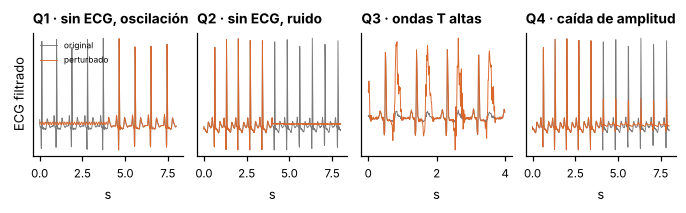

In [5]:
rec_ej = "a03"
fs_e, x0_e, pert_e, f3_e = senales(rec_ej)
fijar({})
k_e = detect_r_peaks(x0_e, fs_e)
mid_e = len(x0_e) // 2
n_e = int(DUR_TRAMO * fs_e)
fig, axs = plt.subplots(1, 4, figsize=(ANCHO, 2.0))
tramos = {"Q1": (n_e - int(4 * fs_e), n_e + int(4 * fs_e)), "Q2": (mid_e - int(4 * fs_e), mid_e + int(4 * fs_e)),
          "Q3": (int(k_e[200]) - int(0.5 * fs_e), int(k_e[200]) + int(3.5 * fs_e)), "Q4": (mid_e - int(4 * fs_e), mid_e + int(4 * fs_e))}
for ax, q in zip(axs, QS):
    a, b = tramos[q]
    tt = np.arange(a, b) / fs_e - a / fs_e
    ax.plot(tt, x0_e[a:b], color=GRIS, lw=0.6, label="original")
    ax.plot(tt, pert_e[q][0][a:b], color=APNEA, lw=0.6, label="perturbado")
    ax.set(title=NOMBRE_Q[q], xlabel="s", yticks=[])
axs[0].set_ylabel("ECG filtrado")
axs[0].legend(fontsize=5.5)
fig.tight_layout()
save(fig, "09_perturbaciones")

**¿Protege cada etapa?** Para cada etapa y cada una de sus pruebas, se compara el cambio sin la etapa con el cambio con ella. Cada persona aporta la mediana de sus noches. Prueba de signos unilateral (la etapa protege si sin ella cambian más latidos) y Holm sobre las 8 combinaciones.

In [6]:
PIV = {q: EST.pivot(index="record", columns="versión", values=q) for q in QS}


def signos(d_reg, alternativa="greater"):
    """Prueba de signos sobre las personas: cada persona aporta la mediana de sus noches; d > 0 favorece a la etapa."""
    d_p = d_reg.groupby(SUJETO.reindex(d_reg.index).to_numpy()).median().dropna()
    d_p = d_p[d_p != 0]
    a = int((d_p > 0).sum())
    return a, len(d_p), (binomtest(a, len(d_p), 0.5, alternative=alternativa).pvalue if len(d_p) else 1.0)


RES_S = {f"{e} · {q}": signos(PIV[q][f"sin {e}"] - PIV[q]["completo"]) for e, qs in PRUEBAS_ETAPA.items() for q in qs}
PH_S = holm({k: v[2] for k, v in RES_S.items()})
TAB_S = pd.DataFrame({"personas a favor de la etapa": {k: f"{v[0]} de {v[1]}" for k, v in RES_S.items()},
                      "% que cambian sin la etapa (mediana)": {k: PIV[k[-2:]][f"sin {k[:-5]}"].median() for k in RES_S},
                      "con la etapa (mediana)": {k: PIV[k[-2:]]["completo"].median() for k in RES_S},
                      "p (signos)": {k: v[2] for k, v in RES_S.items()}, "p de Holm": PH_S})
TAB_S["protege"] = np.where(TAB_S["p de Holm"] < 0.05, "sí", "no")
PROTEGE_EST = {e: any(TAB_S.loc[f"{e} · {q}", "protege"] == "sí" for q in qs) for e, qs in PRUEBAS_ETAPA.items()}
TAB_S.round(4)

,personas a favor de la etapa,% que cambian sin la etapa (mediana),con la etapa (mediana),p (signos),p de Holm,protege
reaprendizaje · Q4,15 de 19,0.7093,0.0040,0.0096,0.0384,sí
pulso aislado · Q1,4 de 8,0.0000,0.0000,0.6367,1.0000,no
pulso aislado · Q2,0 de 14,0.3890,0.3897,1.0000,1.0000,no
piso de energía · Q1,6 de 7,0.0000,0.0000,0.0625,0.1875,no
piso de energía · Q2,19 de 19,3.0165,0.3897,0.0000,0.0000,sí
ventana según el ritmo · Q3,15 de 18,1.1298,1.0536,0.0038,0.0188,sí
forma · Q3,19 de 19,3.5438,1.0536,0.0000,0.0000,sí
energía rápida · Q3,17 de 19,3.3211,1.0536,0.0004,0.0022,sí


**¿Alguna etapa empeora la salida en las otras pruebas?** Se informa, pero no cambia la decisión. Misma prueba de signos, en la dirección contraria (sin la etapa cambian menos latidos), con Holm sobre las 16 combinaciones restantes.

In [7]:
RES_O = {f"{e} · {q}": signos(PIV[q]["completo"] - PIV[q][f"sin {e}"]) for e in ETAPAS for q in QS if q not in PRUEBAS_ETAPA[e]}
PH_O = holm({k: v[2] for k, v in RES_O.items()})
TAB_O = pd.DataFrame({"personas en que la etapa empeora": {k: f"{v[0]} de {v[1]}" for k, v in RES_O.items()},
                      "% que cambian sin la etapa (mediana)": {k: PIV[k[-2:]][f"sin {k[:-5]}"].median() for k in RES_O},
                      "con la etapa (mediana)": {k: PIV[k[-2:]]["completo"].median() for k in RES_O},
                      "p (signos)": {k: v[2] for k, v in RES_O.items()}, "p de Holm": PH_O})
TAB_O["empeora de forma demostrable"] = np.where(TAB_O["p de Holm"] < 0.05, "sí", "no")
TAB_O.round(4)

,personas en que la etapa empeora,% que cambian sin la etapa (mediana),con la etapa (mediana),p (signos),p de Holm,empeora de forma demostrable
reaprendizaje · Q1,0 de 8,0.0000,0.0000,1.0000,1.0000,no
reaprendizaje · Q2,19 de 19,0.0000,0.3897,0.0000,0.0000,sí
reaprendizaje · Q3,3 de 19,7.8652,1.0536,0.9996,1.0000,no
pulso aislado · Q3,12 de 17,1.1751,1.0536,0.0717,0.3587,no
pulso aislado · Q4,3 de 14,0.0099,0.0040,0.9935,1.0000,no
piso de energía · Q3,2 de 7,1.0425,1.0536,0.9375,1.0000,no
piso de energía · Q4,13 de 14,0.0031,0.0040,0.0009,0.0110,sí
ventana según el ritmo · Q1,7 de 7,0.0000,0.0000,0.0078,0.0703,no
ventana según el ritmo · Q2,19 de 19,0.3654,0.3897,0.0000,0.0000,sí
ventana según el ritmo · Q4,12 de 16,0.0042,0.0040,0.0384,0.2304,no


PosixPath('/home/user/TP-PSB-G8/informe/figuras/09_estres_qrs.png')

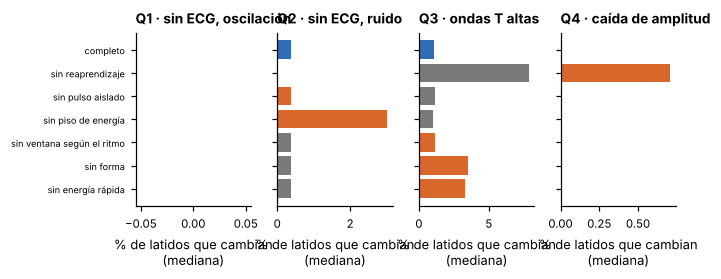

In [8]:
fig, axs = plt.subplots(1, 4, figsize=(ANCHO, 2.6), sharey=False)
orden = list(VERSIONES)
for ax, q in zip(axs, QS):
    med = PIV[q][orden].median()
    colores = [NORMAL if v == "completo" else (APNEA if v[4:] in PRUEBAS_ETAPA and q in PRUEBAS_ETAPA[v[4:]] else GRIS) for v in orden]
    ax.barh(range(len(orden)), med.to_numpy(), color=colores)
    ax.set_yticks(range(len(orden)))
    ax.set_yticklabels(orden if q == "Q1" else [], fontsize=6)
    ax.invert_yaxis()
    ax.set(title=NOMBRE_Q[q], xlabel="% de latidos que cambian\n(mediana)")
fig.tight_layout()
save(fig, "09_estres_qrs")

En la figura, en rojo las versiones sin una etapa que se prueba en ese panel, y en verde el detector completo.

**Qué se ve.**
- **Protegen cinco etapas**, cada una en su prueba, con Holm:
  - el reaprendizaje en Q4, en 15 de 19 personas: sin él cambia el 0,71 % de los latidos, y con él el 0,004 %;
  - el piso en Q2, en las 19 personas: 3,0 % contra 0,39 %;
  - la ventana según el ritmo en Q3, en 15 de 18 personas;
  - la forma en Q3, en las 19 personas: 3,5 % contra 1,1 %;
  - la energía rápida en Q3, en 17 de 19 personas: 3,3 % contra 1,1 %.
- **El pulso aislado no protege en ninguna de sus pruebas.** En Q1, el piso ya alcanza para que no se marquen latidos en la oscilación. En Q2 cambia apenas más con él (0,390 % contra 0,389 %).
- **Varias etapas tienen un costo chico en otras pruebas**, y ese costo es demostrable porque se repite en casi todas las personas:
  - con el reaprendizaje, el detector se vuelve a ajustar dentro del tramo de ruido de Q2 y marca algunos latidos falsos (0,39 %). Sin él, se queda ciego durante el ruido, que en ese tramo es lo correcto;
  - la forma y la ventana según el ritmo suben el cambio en Q2 de 0,365 % a 0,390 %; la energía rápida lo sube apenas (de 0,3895 % a 0,3897 %);
  - la forma también lo sube en Q1, aunque la mediana sigue en cero;
  - el piso sube el cambio en Q4 de 0,003 % a 0,004 %, y la energía rápida lo sube apenas.

  Son diferencias de centésimas o milésimas de punto, contra protecciones de varios puntos. Se informan y no cambian la decisión, como fija el criterio.

## 2. ¿Alguna etapa empeora el detector?

Cada etapa se saca del detector final de `08`, de a una, y se arma todo el pipeline: latidos, RR, EDR y la feature C. Se comparan:
- la exactitud en validación cruzada por personas, con el bootstrap que repite el ajuste en cada sorteo (2000 sorteos);
- P2 (ρ entre el nivel nocturno de la EDR y el % de apnea; 4000 sorteos).

La diferencia se escribe completo − sin la etapa: **un valor negativo quiere decir que la etapa empeora**. Holm sobre las 12 comparaciones. La exactitud se compara en los minutos que las dos versiones clasifican, y P2 en las noches que tienen nivel de la EDR con las dos. Si una versión casi no encuentra latidos en una noche, no queda ninguna serie que analizar: esa noche no tiene minutos para esa versión, y la tabla de abajo lo muestra.

In [9]:
def tabla_registro(args):
    rec, cambios = args
    fijar(cambios)
    try:
        t = minute_table(rec, series=record_series(rec, **FINAL_EDR), detrend_type=DT)
    except (IndexError, KeyError):   # la versión casi no encuentra latidos: no queda ninguna serie, o ningún minuto, que analizar
        t = pd.DataFrame()
    fijar({})
    return t


def tablas(cambios):
    with ProcessPoolExecutor(4) as ex:
        t = pd.concat(list(ex.map(tabla_registro, [(r, cambios) for r in DEV])), ignore_index=True)
    return t.assign(subject=t.record.map(SUJETO))


def con_ev(t, max_corrected=MC):
    e = t[evaluable(t, max_corrected)]
    return e[np.isfinite(e.P_RR) & np.isfinite(e.EDR_noche)].reset_index(drop=True)


def parametros(T_):
    e = con_ev(T_)
    w = float(GRILLA_W[int(np.argmax([auc(c_score(e, fit_c(e, w_, max_corrected=MC)), e.label) for w_ in GRILLA_W]))])
    p = fit_c(e, w, max_corrected=MC)
    return p, youden_threshold(c_score(e, p).to_numpy(), e.label.to_numpy())


T_V = {v: tablas(c) for v, c in VERSIONES.items()}
p_c, u_c = parametros(T_V["completo"])
print("el completo es el detector final de 08 (mismos parámetros):",
      bool(np.isclose(u_c, PARAMS_08["umbral"]) and all(np.isclose(p_c[k], PARAMS_08[k]) for k in ("mu1", "s1", "mu2", "s2", "w"))))
pd.DataFrame({v: {"minutos evaluables": len(con_ev(t)), "registros con minutos": t.record.nunique(),
                  "registros sin serie": ", ".join(sorted(set(DEV) - set(t.record)))} for v, t in T_V.items()}).T

/usr/local/lib/python3.13/site-packages/numpy/_core/fromnumeric.py:3862: RuntimeWarning: Mean of empty slice
  return _methods._mean(a, axis=axis, dtype=dtype,


/usr/local/lib/python3.13/site-packages/numpy/_core/_methods.py:142: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


el completo es el detector final de 08 (mismos parámetros): True


,minutos evaluables,registros con minutos,registros sin serie
completo,22772,47,
sin reaprendizaje,17958,39,"a03, c02, c06, c09, c10, x03, x04, x35"
sin pulso aislado,22768,47,
sin piso de energía,22768,47,
sin ventana según el ritmo,22772,47,
sin forma,22762,47,
sin energía rápida,22588,47,


In [10]:
def marcar(E_a, E_b):
    clave = lambda e: pd.MultiIndex.from_frame(e[["record", "minute"]])
    comun = clave(E_a).intersection(clave(E_b))
    return E_a.assign(com=clave(E_a).isin(comun)), E_b.assign(com=clave(E_b).isin(comun))


_B = {}


def _trabajo_ni(semillas):
    Ea, Eb = _B["E"]; personas = _B["personas"]
    out = []
    for s in semillas:
        mu = np.random.default_rng([2026, s]).choice(personas, len(personas))
        ra, rb = cv_c(replicar_personas(Ea, mu)), cv_c(replicar_personas(Eb, mu))
        oka, okb = (ra.pred == ra.label).to_numpy() & ra.com.to_numpy(), (rb.pred == rb.label).to_numpy() & rb.com.to_numpy()
        out.append(oka.sum() / ra.com.sum() - okb.sum() / rb.com.sum())
    return out


def boot_ni(Ea, Eb, n=None):
    """Distribución bootstrap de la diferencia de exactitud (a − b) en los minutos comunes, repitiendo la validación cruzada."""
    n = n or (40 if RAPIDO else 2000)
    _B.update(E=(Ea, Eb), personas=np.asarray(PERSONAS))
    with ProcessPoolExecutor(4) as ex:
        return np.array([x for b in ex.map(_trabajo_ni, np.array_split(np.arange(n), 40)) for x in b])


def dif_exactitud(E_a, E_b):
    Ea, Eb = marcar(E_a, E_b)
    m_ = cv_c(E_a).merge(cv_c(E_b), on=["record", "minute"], suffixes=("_a", "_b"))
    return float((m_.pred_a == m_.label_a).mean() - (m_.pred_b == m_.label_b).mean()), boot_ni(Ea, Eb)


FRAC = pd.Series({r: float((load_apnea_labels(r)[load_apnea_labels(r) >= 0] == 1).mean()) for r in DEV})
recs = np.asarray(DEV); frac = FRAC.reindex(recs).to_numpy()
SORTEOS = sorteos_personas(PERSONAS, n=200 if RAPIDO else 4000, semilla=2026)
filas_de = {u: np.flatnonzero(SUJETO.reindex(recs).to_numpy() == u) for u in PERSONAS}
idx_sorteos = [np.concatenate([filas_de[u] for u in so]) for so in SORTEOS]


def nivel(T_):
    return T_.groupby("record").EDR_noche.first().reindex(recs).to_numpy()


def rho(a, b, i=None):
    """ρ de Spearman con las noches que tienen los dos valores (y, si se da, solo las del sorteo i)."""
    i = np.arange(len(a)) if i is None else i
    ok = np.isfinite(a[i]) & np.isfinite(b[i])
    return spearmanr(a[i][ok], b[i][ok])[0]


E_C = con_ev(T_V["completo"])
RES_NI = {}
for e in ETAPAS:
    RES_NI[f"exactitud · {e}"] = dif_exactitud(E_C, con_ev(T_V[f"sin {e}"]))
for e in ETAPAS:
    na, nb = nivel(T_V["completo"]), nivel(T_V[f"sin {e}"])
    na = np.where(np.isfinite(nb), na, np.nan)              # las mismas noches para las dos versiones
    RES_NI[f"P2 · {e}"] = (rho(na, frac) - rho(nb, frac),
                           np.array([rho(na, frac, i) - rho(nb, frac, i) for i in idx_sorteos]))
PH_NI = holm({k: p_bootstrap(b) for k, (_, b) in RES_NI.items()})
TAB_NI = pd.DataFrame({"completo − sin la etapa": {k: v[0] for k, v in RES_NI.items()},
                       "IC 95 %": {k: f"{np.nanpercentile(v[1], 2.5):+.3f} a {np.nanpercentile(v[1], 97.5):+.3f}" for k, v in RES_NI.items()},
                       "p": {k: p_bootstrap(v[1]) for k, v in RES_NI.items()}, "p de Holm": PH_NI})
TAB_NI["p de Holm"] = TAB_NI["p de Holm"].fillna(1.0)
TAB_NI["la etapa empeora de forma demostrable"] = np.where((TAB_NI["completo − sin la etapa"] < 0) & (TAB_NI["p de Holm"] < 0.05), "sí", "no")
TAB_NI["la etapa mejora de forma demostrable"] = np.where((TAB_NI["completo − sin la etapa"] > 0) & (TAB_NI["p de Holm"] < 0.05), "sí", "no")
TAB_NI.round(4)

,completo − sin la etapa,IC 95 %,p,p de Holm,la etapa empeora de forma demostrable,la etapa mejora de forma demostrable
exactitud · reaprendizaje,-0.0116,-0.068 a +0.048,0.9780,1.0,no,no
exactitud · pulso aislado,0.0004,-0.004 a +0.003,0.9980,1.0,no,no
exactitud · piso de energía,-0.0009,-0.003 a +0.004,0.6550,1.0,no,no
exactitud · ventana según el ritmo,0.0000,-0.003 a +0.003,0.6740,1.0,no,no
exactitud · forma,-0.0121,-0.004 a +0.005,0.7000,1.0,no,no
exactitud · energía rápida,0.0008,-0.007 a +0.010,0.9990,1.0,no,no
P2 · reaprendizaje,0.2082,+0.000 a +0.522,0.1325,1.0,no,no
P2 · pulso aislado,0.0005,+0.000 a +0.004,1.0000,1.0,no,no
P2 · piso de energía,0.0000,+0.000 a +0.000,NaN,1.0,no,no
P2 · ventana según el ritmo,0.0036,+0.000 a +0.017,0.6760,1.0,no,no


Una diferencia de P2 exactamente cero quiere decir que la etapa no cambia el nivel de la EDR de ninguna noche; entonces el bootstrap no tiene variación y no hay p (se toma p de Holm = 1).

**¿De dónde vienen las diferencias de exactitud?** Para cada etapa: en qué grupos de la validación cruzada cambia el peso w elegido al sacarla, y cuántos minutos cambian de decisión.

In [11]:
r_c = cv_c(E_C)
w_c = r_c.groupby("grupo").w.first()
filas = []
for e in ETAPAS:
    r_v = cv_c(con_ev(T_V[f"sin {e}"]))
    w_v = r_v.groupby("grupo").w.first()
    g_cambia = [g for g in w_c.index if g in w_v.index and w_c[g] != w_v[g]]
    m_ = r_c.merge(r_v, on=["record", "minute"], suffixes=("_a", "_b"))
    cambia = (m_.pred_a != m_.pred_b).to_numpy()
    filas.append({"etapa": e, "grupos en que cambia w": ", ".join(f"{g}: {w_c[g]:.2f} → {w_v[g]:.2f}" for g in g_cambia) or "ninguno",
                  "minutos que cambian de decisión": int(cambia.sum()),
                  "de ellos, en esos grupos": int(cambia[m_.grupo_a.isin(g_cambia).to_numpy()].sum())})
pd.DataFrame(filas).set_index("etapa")

,grupos en que cambia w,minutos que cambian de decisión,"de ellos, en esos grupos"
etapa,,,
reaprendizaje,"0: 1.25 → 0.50, 1: 0.50 → 1.00, 2: 1.00 → 0.50...",752,752
pulso aislado,ninguno,36,0
piso de energía,ninguno,123,0
ventana según el ritmo,ninguno,9,0
forma,1: 0.50 → 0.75,385,326
energía rápida,ninguno,147,0


**Qué se ve.**
- **Ninguna etapa empeora el detector de forma demostrable**, ni en exactitud ni en P2 (p de Holm = 1 en todas).
- **Dos diferencias de exactitud parecen grandes, pero no lo son:**
  - *La forma* (−0,012) queda incluso fuera de su intervalo. No viene de los latidos sino de la elección del peso: en un grupo de la validación cruzada, sacar la forma mueve unos pocos minutos y la grilla elige otro w, con otro umbral, y ahí cambia de decisión la mayoría de los minutos (tabla de arriba). El bootstrap, que repite el ajuste con otras personas, muestra que ese salto casi nunca se repite: el intervalo va de −0,004 a +0,005.
  - *El reaprendizaje* (−0,012) se compara solo en las 39 noches donde la versión sin él deja minutos, porque en las otras 8 no queda nada que clasificar. Su intervalo es muy ancho (−0,068 a +0,048).
- **Sin el reaprendizaje, P2 baja 0,21**, porque se pierden noches enteras, aunque no es demostrable con Holm.

## 3. Decisión

Una etapa **se mantiene** si protege y no empeora el detector de forma demostrable. Protege si lo muestra alguna de sus pruebas de estrés o, con el agregado, una falla real. Si empeora, sale. Si no protege, pasa a la regla de sencillez de `07`: se mantiene solo si mejora de forma demostrable (b) la detección de los latidos, medida como el % medio de RR corregidos por registro, o (c) la exactitud del detector. Se aplica la regla con el agregado, y se muestra también qué decidía la regla registrada antes.

In [12]:
RC = EST.pivot(index="record", columns="versión", values="% RR corregidos").reindex(recs)
RES_B = {}
for e in ETAPAS:
    d = (RC["completo"] - RC[f"sin {e}"]).to_numpy()      # negativo: con la etapa hay menos RR corregidos
    RES_B[e] = (float(np.mean(d)), np.array([np.mean(d[i]) for i in idx_sorteos]))
PH_B = holm({k: p_bootstrap(b) for k, (_, b) in RES_B.items()})
TAB_B = pd.DataFrame({"% RR corregidos: completo − sin la etapa": {k: v[0] for k, v in RES_B.items()},
                      "IC 95 %": {k: f"{np.percentile(v[1], 2.5):+.3f} a {np.percentile(v[1], 97.5):+.3f}" for k, v in RES_B.items()},
                      "p": {k: p_bootstrap(v[1]) for k, v in RES_B.items()}, "p de Holm": PH_B})
TAB_B["p de Holm"] = TAB_B["p de Holm"].fillna(1.0)
TAB_B["% RR corregidos sin la etapa (mediana)"] = {e: RC[f"sin {e}"].median() for e in ETAPAS}
TAB_B["con la etapa (mediana)"] = RC["completo"].median()
print("Medida (b), la detección de los latidos (se usa solo para las etapas que no protegen):")
TAB_B.round(4)

Medida (b), la detección de los latidos (se usa solo para las etapas que no protegen):


,% RR corregidos: completo − sin la etapa,IC 95 %,p,p de Holm,% RR corregidos sin la etapa (mediana),con la etapa (mediana)
reaprendizaje,-11.4314,-21.261 a -3.643,0.0005,0.0005,0.4431,0.3705
pulso aislado,-0.0346,-0.050 a -0.021,0.0000,0.0000,0.4197,0.3705
piso de energía,-0.0382,-0.108 a -0.002,0.0000,0.0000,0.3894,0.3705
ventana según el ritmo,-0.0457,-0.074 a -0.023,0.0000,0.0000,0.4378,0.3705
forma,-0.0776,-0.113 a -0.046,0.0000,0.0000,0.4656,0.3705
energía rápida,-1.3034,-4.065 a -0.006,0.0000,0.0000,0.4146,0.3705


**Fallas reales (agregado posterior a la prueba rápida).** Una etapa también protege si, en el ECG original, sin ella alguna noche de desarrollo queda más de un punto peor en % de RR corregidos que con ella. Es el umbral con que `02` decidió que un registro empeoraba.

In [13]:
PEOR = RC.drop(columns="completo").sub(RC["completo"], axis=0)
FALLA_REAL = {e: sorted(PEOR.index[PEOR[f"sin {e}"] > 1]) for e in ETAPAS}
pd.DataFrame({"noches más de un punto peor sin la etapa": {e: ", ".join(v) or "ninguna" for e, v in FALLA_REAL.items()},
              "peor diferencia (puntos de % de RR corregidos)": {e: PEOR[f"sin {e}"].max() for e in ETAPAS},
              "protege por las pruebas de estrés": {e: "sí" if PROTEGE_EST[e] else "no" for e in ETAPAS},
              "protege por una falla real": {e: "sí" if FALLA_REAL[e] else "no" for e in ETAPAS}}).round(2)

,noches más de un punto peor sin la etapa,peor diferencia (puntos de % de RR corregidos),protege por las pruebas de estrés,protege por una falla real
reaprendizaje,"a03, c01, c02, c06, c09, c10, x03, x04, x18, x35",78.16,sí,sí
pulso aislado,ninguna,0.18,no,no
piso de energía,x28,1.52,sí,sí
ventana según el ritmo,ninguna,0.41,sí,no
forma,ninguna,0.51,sí,no
energía rápida,x17,60.82,sí,sí


In [14]:
def decidir(e, protege):
    empeora = any(TAB_NI.loc[f"{m} · {e}", "la etapa empeora de forma demostrable"] == "sí" for m in ("exactitud", "P2"))
    if empeora:
        return "sale", "empeora el detector de forma demostrable"
    if protege:
        return "se mantiene", "protege y no empeora el detector"
    mejora_b = RES_B[e][0] < 0 and PH_B.get(e, 1.0) < 0.05
    mejora_c = TAB_NI.loc[f"exactitud · {e}", "la etapa mejora de forma demostrable"] == "sí"
    if mejora_b or mejora_c:
        return "se mantiene", "no protege, pero mejora de forma demostrable " + ("la detección de los latidos" if mejora_b else "el detector")
    return "sale", "no protege y no mejora de forma demostrable ni la detección ni el detector"


PROTEGE = {e: PROTEGE_EST[e] or bool(FALLA_REAL[e]) for e in ETAPAS}
filas = []
for e in ETAPAS:
    d_reg, pq_reg = decidir(e, PROTEGE_EST[e])
    d_fin, pq_fin = decidir(e, PROTEGE[e])
    filas.append({"etapa": e, "protege (estrés)": "sí" if PROTEGE_EST[e] else "no", "protege (falla real)": "sí" if FALLA_REAL[e] else "no",
                  "decisión con la regla registrada antes": d_reg, "decisión con el agregado": d_fin, "por qué": pq_fin})
DEC = pd.DataFrame(filas).set_index("etapa")
SALEN = [e for e in ETAPAS if DEC.loc[e, "decisión con el agregado"] == "sale"]
DEC

,protege (estrés),protege (falla real),decisión con la regla registrada antes,decisión con el agregado,por qué
etapa,,,,,
reaprendizaje,sí,sí,se mantiene,se mantiene,protege y no empeora el detector
pulso aislado,no,no,se mantiene,se mantiene,"no protege, pero mejora de forma demostrable l..."
piso de energía,sí,sí,se mantiene,se mantiene,protege y no empeora el detector
ventana según el ritmo,sí,no,se mantiene,se mantiene,protege y no empeora el detector
forma,sí,no,se mantiene,se mantiene,protege y no empeora el detector
energía rápida,sí,sí,se mantiene,se mantiene,protege y no empeora el detector


**Chequeo de la combinación.** Si sale más de una etapa, el detector resultante se compara con el completo en las cuatro pruebas de estrés. Si en alguna protege menos de forma demostrable, se restituye la etapa que, agregada sola, más reduce el cambio mediano en esa prueba, y se repite. Si sale alguna etapa, el resultante se compara además con el final de `08` en exactitud.

In [15]:
REGISTRO_COMB = []
while len(SALEN) > 1:
    est_r = correr_estres({"completo": {}, "resultante": sin(*SALEN)})
    peor = []
    for q in QS:
        pv = est_r.pivot(index="record", columns="versión", values=q)
        a, n, p = signos(pv["resultante"] - pv["completo"])
        REGISTRO_COMB.append({"etapas que salen": ", ".join(SALEN), "prueba": NOMBRE_Q[q], "personas en que protege menos": f"{a} de {n}", "p": p})
        if p < 0.05:
            peor.append(q)
    if not peor:
        break
    q = peor[0]
    est_v = correr_estres({f"vuelve {e}": sin(*[s for s in SALEN if s != e]) for e in SALEN})
    vuelve = est_v.groupby("versión")[q].median().idxmin()[len("vuelve "):]
    REGISTRO_COMB.append({"etapas que salen": ", ".join(SALEN), "prueba": NOMBRE_Q[q], "personas en que protege menos": "—",
                          "p": np.nan, "se restituye": vuelve})
    SALEN.remove(vuelve)
if REGISTRO_COMB:
    display(pd.DataFrame(REGISTRO_COMB))
else:
    print(f"{'Sale una sola etapa' if len(SALEN) == 1 else 'No sale ninguna etapa'}: no hace falta el chequeo en las pruebas de estrés.")

if SALEN:
    T_R = tablas(sin(*SALEN))
    d_r, b_r = dif_exactitud(E_C, con_ev(T_R))
    print(f"final de 08 − resultante, exactitud: {d_r:+.4f} (IC 95 % {np.percentile(b_r, 2.5):+.3f} a {np.percentile(b_r, 97.5):+.3f}), p = {p_bootstrap(b_r):.3f}")
else:
    T_R = T_V["completo"]
print("Etapas que salen del detector de QRS:", SALEN or "ninguna")

No sale ninguna etapa: no hace falta el chequeo en las pruebas de estrés.
Etapas que salen del detector de QRS: ninguna


In [16]:
ETAPAS_QRS = {e: e not in SALEN for e in ETAPAS}
PARAMS_09 = dict(PARAMS_08)
if SALEN:
    p_r, u_r = parametros(T_R)
    PARAMS_09.update({k: p_r[k] for k in ("mu1", "s1", "mu2", "s2", "w")}, umbral=u_r)
    PARAMS_09["fijado_con"] = "47 registros de desarrollo (notebooks/09_robustez_qrs.ipynb, sección 3)"
PARAMS_09["etapas_qrs"] = {"pan_tompkins_1985": True, **{e.replace(" ", "_"): v for e, v in ETAPAS_QRS.items()},
                           "revisadas_en": "notebooks/09_robustez_qrs.ipynb"}
if not RAPIDO:
    save_params(ROOT / "docs" / "parametros_final.json", PARAMS_09)
print(json.dumps(PARAMS_09, indent=2, ensure_ascii=False))

{
  "feature": "C(m) = (P_RR(m) - mu1)/s1 + w * (mediana_noche(P_EDR) - mu2)/s2",
  "mu1": -1.4915729639776574,
  "s1": 0.5902302539907761,
  "mu2": -1.9919863678366045,
  "s2": 0.5992052156417715,
  "w": 1.0,
  "umbral": 0.48134981497878243,
  "banda_hz": [
    0.01,
    0.05
  ],
  "banda_efectiva_hz": [
    0.0167,
    0.05
  ],
  "ventana_s": 240,
  "etapas": {
    "refinamiento_pico_r": true,
    "wiener_edr": false,
    "excluir_ectopicos_edr": true,
    "hampel_edr": true,
    "aberrantes_varon_edr": false,
    "edr_relativa": true,
    "interpolacion": "cubic",
    "tendencia_welch": "linear",
    "max_rr_corregidos_por_minuto": 0.2,
    "confianza": false
  },
  "fijado_con": "47 registros de desarrollo (notebooks/08_edr_nivel_noche.ipynb, sección 7)",
  "evaluacion": "solo validación cruzada por personas en desarrollo; sin evaluación independiente todavía",
  "etapas_qrs": {
    "pan_tompkins_1985": true,
    "reaprendizaje": true,
    "pulso_aislado": true,
    "piso_de_ener

**Qué se ve.**
- **Se mantienen las seis etapas del detector de QRS**, con la regla registrada antes y también con el agregado de las fallas reales. En esta corrida el agregado no cambió ninguna decisión: con las 47 noches, el reaprendizaje también protege en Q4.
- **Cinco etapas protegen y no empeoran el detector:**
  - el reaprendizaje, por Q4 y por 10 noches reales que sin él quedan casi sin latidos;
  - el piso, por Q2 y por x28;
  - la ventana según el ritmo y la forma, por Q3;
  - la energía rápida, por Q3 y por x17.
- **El pulso aislado no protege**, pero se mantiene por la regla de sencillez de `07`: mejora la detección de los latidos de forma demostrable, con 0,035 puntos menos de RR corregidos (p de Holm < 0,001). Es una mejora chica pero consistente.
- **No sale ninguna etapa**, así que el detector final de `08` no cambia, ni sus parámetros. A `docs/parametros_final.json` se le agrega la lista de las etapas del QRS revisadas.
- Algunas etapas tienen un costo chico en otras pruebas de estrés (sección 1). Se informa como limitación.